In [3]:
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# the notebook can live in lab3/ or lab3/code; always work from lab3/
if os.path.basename(os.getcwd()) == "code":
    os.chdir("..")
sys.path.append("code")  # so we can import our own scripts

from similarity import similarity
from kmeans_stability import load_binary_ling, DATA_PATH

# Introduction

In Lab 2, we found that the dialect survey seemed to split into three main regional groups: the Northeast, the Midwest/Rust Belt, and a more general American group that was strongest in the Southeast. However, choosing the number of clusters was one of the shakiest parts of that analysis. The elbow plot did not have a super clear bend, and the silhouette scores for $k = 3$ and $k = 5$ were almost tied. In this lab, we take a closer look at that question using the stability method from Ben-Hur (2002).

In this method, if a clustering with $k$ groups is capturing real structure in the data, then clustering two different random subsamples should give us almost the same answer for the people who show up in both. If the $k$ number of clusters is too big, k-means is forced to split up a real group, and where it makes that split may change which people--who should be in the same group--happened to land in the subsample. So the two clusterings will disagree. By repeating this many times, we get a whole distribution of similarity scores for each $k$, and the paper suggests picking the largest $k$ where these scores are still bunched up near 1.

For this lab, we use the binary-coded version of the survey data, which has 45,152 respondents and 468 binary columns. Each column is one answer option to one question, which is the same kind of one-hot coding used in Lab 2. We set the maximum number of clusters to $k_{max} = 10$, the number of repeats to $B = 100$, and the sampling fraction to $m = 0.8$, which is the largest value allowed.

This takes heavy computation. First, with $m = 0.8$ the two subsamples share about 29,000 people, and the most obvious way to compare two clusterings would need a $29{,}000 \times 29{,}000$ matrix that takes up about 6 GB. Second, the whole procedure needs 1,800 k-means fits on about 36,000 people each. In the next section we describe a similarity function that gets around the giant matrix and runs in time that grows linearly with the number of people. Then we describe how we ran Algorithm 1 in parallel on the SCF cluster, and finally we look at the results and what they say about the right number of clusters.

# Similarity implementation

## Choice of similarity measure

We chose the **Jaccard coefficient** as our similarity measure. For any two people and two different clusterings, they can be grouped together both times, grouped together only once, or kept apart both times. The Jaccard coefficient looks at every pair that was grouped together at least once, and asks what fraction of those pairs were grouped together both times:
$$J = \frac{N_{11}}{N_{01} + N_{10} + N_{11}} = \frac{\text{pairs together in both clusterings}}{\text{pairs together in at least one clustering}}.$$
If the two clusterings are exactly the same (even if the clusters have different names), the score is 1. The more they disagree, the closer the score gets to 0.

The Ben-Hur paper gives three options: correlation, matching, and Jaccard. We picked Jaccard mostly because of a problem with matching. Matching also counts pairs that were kept apart both times, and for our data most pairs are kept apart no matter what. With $k = 10$ groups of roughly equal size, any one respondent shares a group with only about 10% of the others, so about 90% of pairs (like a respondent in Boston and one in Atlanta) are apart in both runs whether or not the clustering is stable. Even at $k = 3$, roughly two thirds of pairs are apart in any clustering. These easy pairs would make up most of the matching score. Jaccard ignores them and only looks at the pairs where something interesting happened. The paper also says Jaccard and correlation behave very similarly in practice, so we are not losing much by picking Jaccard over correlation.

## Algorithm

We don't actually need to look at every pair of people. The Jaccard formula only needs three counts: pairs together in both clusterings ($N_{11}$), pairs together in the first one, and pairs together in the second one. These only depend on how many people fall into each combination of clusters, not on who those people are.

So instead of checking every pair, we make a small table. Each row is a cluster from the first clustering, each column is a cluster from the second, and each cell counts how many people landed in that combination. With $k = 10$, this table only has 100 cells. Any group of $n$ people contains $\binom{n}{2} = n(n-1)/2$ pairs. Two people are together in both clusterings exactly when they land in the same cell, so adding up the pairs inside every cell gives the "together in both" count. The row totals are the cluster sizes from the first clustering, so adding up the pairs inside each row gives the "together in the first" count, and the column totals do the same for the second. The paper counts every pair twice (once in each order), but that doubling cancels out when we divide.

So the algorithm goes through the people once to fill in the table, and then adds. The runtime is $O(q + k_1 k_2)$, where $q$ is the number of shared people and $k_1$ and $k_2$ are the numbers of clusters. Since $k$ is at most 10, this grows in a straight line with $q$. Because we only store the small table, we never need the $q \times q$ matrix. For comparison, checking every pair one by one is $O(q^2)$.

## Python implementation

 The loop over people is slow in plain Python, so we compiled the whole calculation (filling the table and adding up the pairs) with Numba's @njit. A small Python wrapper turns both inputs into 64-bit integer arrays, checks that they are the same length, and then calls the compiled function. Using 64-bit integers means the pair counts (around 400 million at $q = 29{,}000$) can't overflow.

On benchmark.py, our function took 1.8262863159179686e-05 seconds (18.3µs) for $q = 5{,}000$ and 5.0687789916992186e-05 (50.7µs) seconds for $q = 29{,}000$. For comparison, the reference smart implementation takes 58 µs and the reference $O(q^2)$ version takes 0.32 s at $q = 29{,}000$.


## Timing on lingBinary for different values of $m$

For each $m$ from 0.2 to 0.8, we drew two subsamples of lingBinary, ran k-means with $k = 10$ on each, and timed similarity function on the shared people, averaged over 1,000 calls. We call the function once before timing so that Numba's one-time compile step isn't counted.

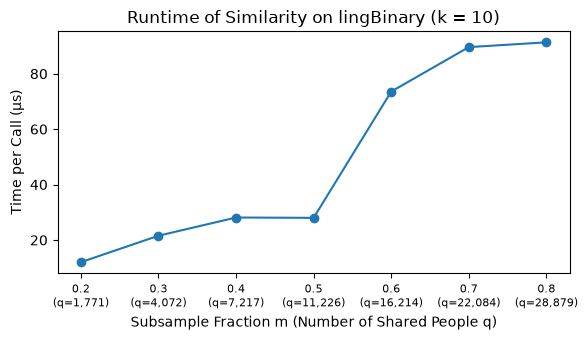

In [10]:
# compile Numba once first so compile time isn't counted
similarity(np.array([0, 1]), np.array([0, 1]))

def average_seconds(func, a, b, repeats):
    """Run func(a, b) many times and return the average time per call."""
    start = time.perf_counter()
    for _ in range(repeats):
        func(a, b)
    return (time.perf_counter() - start) / repeats


lingdata = load_binary_ling(DATA_PATH)
n_people = lingdata.shape[0]
rng = np.random.default_rng(215)

m_values = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
q_values = []
microseconds = []

for m_try in m_values:
    n_try = int(round(m_try * n_people))
    sub1 = np.sort(rng.choice(n_people, size=n_try, replace=False))
    sub2 = np.sort(rng.choice(n_people, size=n_try, replace=False))
    lab1 = KMeans(n_clusters=10, n_init=1, random_state=1).fit_predict(lingdata[sub1])
    lab2 = KMeans(n_clusters=10, n_init=1, random_state=2).fit_predict(lingdata[sub2])
    _, p1, p2 = np.intersect1d(sub1, sub2, assume_unique=True, return_indices=True)

    q_values.append(len(p1))
    microseconds.append(average_seconds(similarity, lab1[p1], lab2[p2], 1000) * 1e6)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(m_values, microseconds, "o-")
ax.set_xticks(m_values, [f"{m}\n(q={q:,})" for m, q in zip(m_values, q_values)], fontsize=8)
ax.set_xlabel("Subsample Fraction m (Number of Shared People q)")
ax.set_ylabel("Time per Call (µs)")
ax.set_title("Runtime of Similarity on lingBinary (k = 10)")
plt.tight_layout()
plt.show()

The number of shared people grows from about 1,800 at $m = 0.2$ to about 29,000 at $m = 0.8$. The runtime grows with $q$, from about 12 µs to about 91 µs, which fits the $O(q)$ algorithm. It grows a bit slower than $q$ because each call has a small fixed setup cost, and the jump between $m = 0.5$ and $m = 0.6$ is likely timing noise from the computer rather than the algorithm. Even the slowest time is far under the 1 ms target, so almost all of Algorithm 1's runtime likley comes from k-means, not from the similarity function.

# Algorithm 1 implementation

We implemented Algorithm 1 in kmeans_stability.py and ran it on the SCF with the job script run.sh using sbatch. For each $k$ from 2 to 10 and each of the 100 repeats, the script draws two subsamples of 80% of the respondents, runs k-means on each, finds the respondents who are in both, and computes the Jaccard similarity of their two sets of labels. The results are saved in `results/S.csv`, with one row per repeat and one column per $k$.

## Choice of k-means parameters

We used the k-means implementation from scikit-learn. For the starting centers, we kept the default k-means++ setting, which spreads out the starting points we assume it finds better solutions than picking them completely at random, where starting centers may begin in the same cluster. We set the number of restarts to n_init=1. We did this so that Algorithm 1 computing time would be as short as possible and to track/measure how repeatable the clustering procedure is. If we ran k-means many times and only kept the best run, we would be hiding some of the instability that comes from where k-means starts. One restart also kept the time cost down to one k-means fit per subsample, which mattered since we needed 1,800 of them. We kept the default stopping rule of at most 300 iterations.

k-means uses squared Euclidean distance, and on 0/1 data this is exactly the number of answer options where two people differ, which is a natural way to measure how different two people's answers are. Lastly, every $(k, i)$ pass gets its own random seed, $215 + 2(kB + i - 1)$. That seed is used for drawing the subsamples, which we want to be different! The two k-means fits use that seed and the seed plus one. This means anyone can rerun the script and get the exact same S.csv.

## Parallelization

All $9 \times 100 = 900$ (from each k value) passes are completely independent of each other, and the only thing they share is the data, which none of them change. So instead of choosing between the inner and outer loop, we combined both loops into one list of 900 tasks, one for each pair of $k$ and repeat, and spread them across cores using joblib.

We decided against parallelizing only the outer loop because that would only give us 9 tasks, so we could never use more than 9 cores. The tasks would also take very different amounts of time, since k-means at $k = 10$ took about three times as long as at $k = 2$ in our tests, so the run would have to wait for the slow $k = 10$ task while the other cores sat idle. Parallelizing only the inner loop would keep the cores busy, but all the workers would have to wait for each other to finish before moving on to the next $k$. With one combined list, there are lots of small tasks and no waiting in between.

On its own, k-means in scikit-learn already tries to use all of the computer's cores at once. Since joblib is also running many k-means fits side by side, each one trying to grab every core would leave the cores overloaded and slow everything down. So we told jobli to limit each k-means fit to a single core (inner_max_num_threads=1). That way, each core works on one k-means fit at a time, and all of the parallel work comes from joblib running many fits at once.

## Runtime and cores

We asked the SCF for **16 cores** (`--cpus-per-task=16` in `run.sh`). Since there are 900 independent tasks, more cores directly cut the runtime, and 16 is a request that the SCF can usually fill without a long wait in the queue. **[FILL IN: change this if you used a different number of cores.]**

The job took **[FILL IN: the runtime from the `real` line at the end of `code/lab3_stability_<jobid>.out`]** to run. For comparison, at about 0.5 to 2 seconds per k-means fit, all 1,800 fits on a single core would take roughly 15 minutes to an hour.

# Result

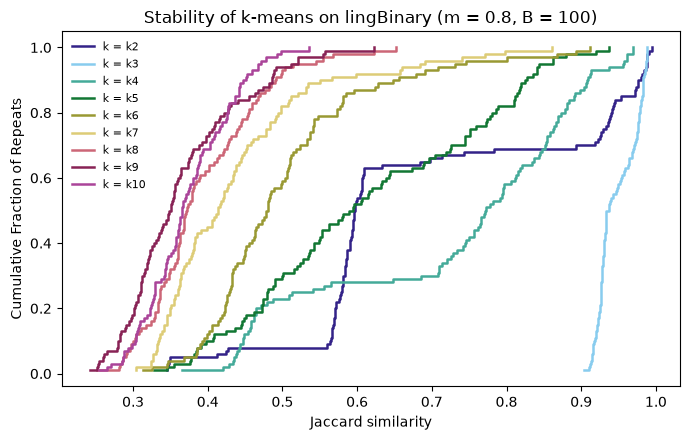

In [ ]:
S = pd.read_csv("results/S.csv", index_col=0)
fig, ax = plt.subplots(figsize=(7, 4.5))
# Paul Tol's "muted" palette: 9 colors that stay distinct for color-blind readers
colors = ["#332288", "#88CCEE", "#44AA99", "#117733", "#999933",
          "#DDCC77", "#CC6677", "#882255", "#AA4499"]


for idx, (color, col) in enumerate(zip(colors, S.columns)):
    # sort the similarities and step up 1/B at each one: the cumulative distribution
    values = np.sort(S[col].to_numpy())
    ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post",
            color=color, lw=1.8,
            label=f"k = {col}")
ax.set_xlabel("Jaccard Similarity")
ax.set_ylabel("Cumulative Fraction of Repeats")
ax.set_title(f"Stability of k-means on lingBinary (m = 0.8, B = {len(S)})")
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

<!-- [CHECK] This discussion was written from a small preliminary run (B = 5).
Once results/S.csv from the SCF is in, compare it to the figure and fix anything
that no longer matches. -->

## Discussion of the plot

The figure shows the cumulative distribution of the 100 similarity scores for each $k$, like Figure 3 in Ben-Hur et al. A stable $k$ has a curve that stays near zero until it gets close to 1 and then shoots straight up. An unstable $k$ has a curve that starts rising much further to the left.

The first thing that stands out is that **$k = 3$ is the only clearly stable choice**. Its scores are tightly bunched near 1 (median **[FILL IN]**), and its curve is the furthest to the right. This means that in almost every repeat, k-means split the respondents into the same three groups.

What surprised us was that **$k = 2$ is actually pretty unstable**. Its scores are spread out: some repeats agree almost perfectly, while many others score much lower. Ben-Hur et al. describe this pattern. When the data has several groups and there isn't one obvious way to merge them into two, the algorithm switches between different two-cluster answers. So our reading is that the data has three main groups, and when k-means is forced to use two, it makes different choices about which two to merge on different subsamples. The low scores at $k = 2$ are what we would expect if there are three clusters.

After $k = 3$, the stability drops off quickly. At $k = 4$ the scores move to the left and spread out, which suggests k-means doesn't have a consistent way to split one of the three groups into two. From about $k = 7$ to $k = 10$, the scores all sit at a low level and the curves almost lie on top of each other, which looks like the uniform random data in the paper's Figure 7. Past that point, k-means seems to be cutting up the data in fairly random ways that change with every subsample.

## Choice of $k$

We would pick **$k = 3$**. It is the largest $k$ whose scores are still bunched up near 1, which is the rule from the paper, and the drop after it is very sharp.

This lines up with Lab 2, where k-means with $k = 3$ split the respondents into the Northeast, the Midwest/Rust Belt, and a general American group that was strongest in the Southeast. In Lab 2 the case for $k = 3$ was weak: the elbow plot didn't have a clear bend, and the silhouette score for $k = 3$ (0.142) barely beat $k = 5$ (0.141). The stability method gives a much clearer answer.

## Do I trust this method?

We trust this method somewhat, but wouldn't rely on it alone.

First, being stable is not the same as being correct. The method measures whether the clustering *procedure* gives the same answer over and over, not whether the clusters are real. For example, k-means will split a long stretched-out cloud of points the same way every time, even if there are no real clusters in it.

Second, the result depends on the algorithm and its settings. What we measured is the stability of *k-means with `k-means++` and one restart*. With more restarts, every $k$ would look more stable. k-means also assumes roughly round clusters of similar size, which isn't a natural fit for 468 binary answers.

Third, the subsamples overlap a lot. With $m = 0.8$, the two subsamples share about 64% of the data, so the two k-means runs see very similar data and will tend to agree even if the structure is weak. A smaller $m$ would be a tougher test.

Fourth, dialects change gradually across the country, so there may not be one "true" $k$, just more or less useful ways to split the data. Deciding where the scores are "bunched near 1" is also done by eye.

That being said, the method doesn't assume anything about the shape of the clusters, works with any clustering algorithm, and directly tests something we want from any useful clustering: that it doesn't depend on which people happened to answer the survey. Here, the answer is clear and matches Lab 2, which makes us more confident in $k = 3$.

## Other ways to choose $k$

One option is to rerun Algorithm 1 on a version of lingBinary where each column is shuffled on its own. This keeps how common each answer is but breaks any connection between questions, so a real $k$ should be much more stable on the real data than on the shuffled data. Another option is the gap statistic, which compares how tight the clusters are to what we would expect with no clusters at all. We could also fit a latent class model (a mixture of independent yes/no variables), which is a natural model for binary survey answers and lets us pick $k$ with BIC.

# Academic Honesty

## Statement

Professor Bin, For these assignments, I will maintain academic integrity and cite all sources that are used including collaborations and LLM use. Academic research honesty is necessary for the ultimate trustworthiness of future scientific knowledge. Being open about assumptions made and how conclusions were drawn can ensure that generalizations are minimized and the statistics can stay as objective as possible. In a world where it can be easy to skew the statistics to support a particular point of view, research performed with integrity can help minimize the misinterpretation of the data. Further, if science was made to understand life's complexities, then it is imperative that assumptions be observed, listed and challenged. Then, we can have a more robust foundation to build future research that can withstand the test of time. We can celebrate inquiry, notice where we fail, and not let that deter us from the pursuit of something a bit greater. Being honest about research means renouncing a fear of failure, being humble about findings, honoring the scientific method, and working toward the betterment of oneself as a scientist and the broader scientific community.

## LLM Usage

### Writinig and Coding

I used Claude's Opus 5.5 for the coding in this lab.  Claude helped me build the walkthrough notebook step by step. I asked it to help in particular with the ways to make the code more efficient, and how to time the process. Once I had the fundamentals for the similarity.py, I also used it for debugging (for example, a Numba compile error and a variable-name error).**

LLM Conversation link: **[FILL IN: share link]**

### Experience

**[FILL IN in your own words: Was it a good experience? Did it save time? Is the code better or worse than if you had written it yourself? Do you fully understand the code? Would you use it again?]**

## Collaborators

None.

# Bibliography

Ben-Hur, A., Elisseeff, A., & Guyon, I. (2002). A stability based method for discovering structure in clustered data. *Pacific Symposium on Biocomputing*, 7, 6–17.